#### Alessia Stefanelli - 615430

# Data Understanding - Dati Tabulari 

#### Esplorazione di ciascun dataset, inizialmente, separatamente

## 1. `patients.csv`

In [1]:
import re
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from collections import defaultdict, Counter

In [2]:
patients_df = pd.read_csv('../datasets/patients.csv')

In [3]:
patients_df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'study_id', 'subject_id', 'ecg_time',
       'ed_stay_id', 'ed_hadm_id', 'hosp_hadm_id', 'diagnosis', 'gender',
       'age', 'anchor_year', 'anchor_age', 'dod', 'ecg_no_within_stay',
       'ecg_taken_in_ed', 'ecg_taken_in_hosp', 'ecg_taken_in_ed_or_hosp',
       'ts_ecg_path'],
      dtype='object')

In [4]:
print("Dim del dataset:", patients_df.shape)

Dim del dataset: (41415, 19)


In [5]:
patients_df[:10]

,Unnamed: 0.1,Unnamed: 0,study_id,subject_id,ecg_time,ed_stay_id,ed_hadm_id,hosp_hadm_id,diagnosis,gender,age,anchor_year,anchor_age,dod,ecg_no_within_stay,ecg_taken_in_ed,ecg_taken_in_hosp,ecg_taken_in_ed_or_hosp,ts_ecg_path
0,0,0,40689238,10000032,2180-07-23 08:44:00,39399961.0,29079034.0,NaN,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J44...",F,52.0,2180.0,52.0,2180-09-09,0,True,False,True,./time-series/10000032_40689238
1,1,4,48446569,10000117,2183-09-18 13:52:00,33176849.0,27988844.0,NaN,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341',...",F,57.0,2174.0,48.0,NaN,0,True,False,True,./time-series/10000117_48446569
2,2,14,47218930,10000764,2132-10-14 19:40:00,35420907.0,27897940.0,NaN,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780...",M,86.0,2132.0,86.0,NaN,0,True,False,True,./time-series/10000764_47218930
3,3,35,42546971,10000980,2188-01-03 12:33:00,34277585.0,29654838.0,NaN,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E11...",F,75.0,2186.0,73.0,2193-08-26,0,True,False,True,./time-series/10000980_42546971
4,4,66,40925049,10001176,2186-11-28 23:16:00,39677610.0,23334588.0,NaN,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219'...",F,64.0,2186.0,64.0,NaN,0,True,False,True,./time-series/10001176_40925049
5,5,70,43576724,10001217,2157-11-18 18:26:00,39866888.0,24597018.0,NaN,"['G35', 'B954', 'G060', 'G936', 'F17200', 'G93...",F,55.0,2157.0,55.0,NaN,0,True,False,True,./time-series/10001217_43576724
6,6,75,44102194,10001401,2131-06-19 17:28:00,31249803.0,26840593.0,NaN,"['I82412', 'Z436', 'R7881', 'T814XXA', 'Z90710...",F,89.0,2131.0,89.0,NaN,0,True,False,True,./time-series/10001401_44102194
7,7,246,47422482,10002221,2200-09-29 16:41:00,34276625.0,21008195.0,NaN,"['I671', 'F329', 'E785', 'K219', 'Z7901', 'Z14...",F,68.0,2200.0,68.0,NaN,0,True,False,True,./time-series/10002221_47422482
8,8,282,43104878,10002430,2125-09-28 16:36:00,31293660.0,24513842.0,NaN,"['E871', 'Z9861', 'I2781', 'E785', 'K219', 'I1...",M,86.0,2125.0,86.0,2130-01-11,0,True,False,True,./time-series/10002430_43104878
9,9,297,47678751,10002528,2168-12-11 00:30:00,34929026.0,23193578.0,NaN,"['R29818', 'F329', 'D509', 'K219', 'D519', 'E8...",F,26.0,2168.0,26.0,NaN,0,True,False,True,./time-series/10002528_47678751



#### **Osservazione**:  
#### `Unnamed: 0` e `Unnamed: 0.1` dovranno essere rimosse durante la Data Preparation,
#### poiche non hanno un significato apparente

In [14]:
for column in patients_df:
    print(f"Valori unici in {column}:")
    print(patients_df[column].unique())
    print("\nConteggio delle frequenze:")
    print(patients_df[column].value_counts())
    print("-" * 50)

Valori unici in Unnamed: 0.1:
[    0     1     2 ... 41412 41413 41414]

Conteggio delle frequenze:
Unnamed: 0.1
0        1
27584    1
27606    1
27607    1
27608    1
        ..
13806    1
13807    1
13808    1
13809    1
41414    1
Name: count, Length: 41415, dtype: int64
--------------------------------------------------
Valori unici in Unnamed: 0:
[     0      4     14 ... 800023 800024 800032]

Conteggio delle frequenze:
Unnamed: 0
0         1
534150    1
534659    1
534667    1
534669    1
         ..
267301    1
267331    1
267342    1
267344    1
800032    1
Name: count, Length: 41415, dtype: int64
--------------------------------------------------
Valori unici in study_id:
[40689238 48446569 47218930 ... 42489677 40734999 41190887]

Conteggio delle frequenze:
study_id
40689238    1
43055960    1
45520839    1
42896557    1
46576848    1
           ..
40191084    1
47742773    1
46940879    1
45467562    1
41190887    1
Name: count, Length: 41415, dtype: int64
-----------------




#### **Osservazione**: 
<div style="font-size:18px; white-space: pre-wrap;">
 - COLONNE da TOGLIERE durante la Data Preparation (non aggiungono informazioni utili per dopo): 
    - `ecg_taken_in_ed_or_hosp` (tutti True), 
    - `ecg_taken_in_ed` (tutti True), 
    - `ed_hadm_id` (dati non utili)
    - `ecg_no_within_stay` (tutti 0) , 
    - `hosp_hadm_id` (id di `ecg_taken_in_hosp`non utili da avere), 
    - `Unnamed 0` e `Unnamed 0.1`
    - `ecg_taken_in_hosp` (squilibrio tra True (39307) e False(2108) troppo alto)
</div>

In [15]:
# Per controllore singolarmente gli attributi
# ['Unnamed: 0.1', 'Unnamed: 0', 'study_id', 'subject_id', 'ecg_time',
#'ed_stay_id', 'ed_hadm_id', 'hosp_hadm_id', 'diagnosis', 'gender',
# 'age', 'anchor_year', 'anchor_age', 'dod', 'ecg_no_within_stay',
# 'ecg_taken_in_ed', 'ecg_taken_in_hosp', 'ecg_taken_in_ed_or_hosp',
# 'ts_ecg_path']
column = 'ecg_taken_in_hosp'
print(f"Valori unici in {column}:")
print(patients_df[column].unique())
print("\nConteggio delle frequenze:")
print(patients_df[column].value_counts())
print("-" * 50)

Valori unici in ecg_taken_in_hosp:
[False  True]

Conteggio delle frequenze:
ecg_taken_in_hosp
False    39307
True      2108
Name: count, dtype: int64
--------------------------------------------------


In [3]:
# Delete per fare meglio analisi succecssive in data understanding
patients_df  = patients_df.drop(columns=["Unnamed: 0", 'Unnamed: 0.1', "ecg_taken_in_ed_or_hosp", 'ecg_taken_in_ed', 'ecg_no_within_stay', 'hosp_hadm_id', 'ed_stay_id', 'ed_hadm_id', 'ecg_taken_in_hosp', 'study_id', 'ts_ecg_path'])

In [21]:
patients_df.columns

Index(['subject_id', 'ecg_time', 'diagnosis', 'gender', 'age', 'anchor_year',
       'anchor_age', 'dod'],
      dtype='object')

In [22]:
# Statistiche per ogni NUMERICAL column per determinare anomalie
patients_df.describe()

,subject_id,age,anchor_year,anchor_age
count,4.141500e+04,41415.000000,41415.000000,41415.000000
mean,1.501484e+07,61.982953,2152.889605,61.107208
std,2.892611e+06,18.827568,23.702419,18.897571
min,1.000003e+07,18.000000,2110.000000,18.000000
25%,1.250300e+07,50.000000,2133.000000,49.000000
50%,1.502321e+07,64.000000,2153.000000,63.000000
75%,1.752916e+07,77.000000,2173.000000,76.000000
max,1.999999e+07,100.000000,2208.000000,91.000000


In [23]:
# Info sul dataset
patients_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41415 entries, 0 to 41414
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   subject_id   41415 non-null  int64  
 1   ecg_time     41415 non-null  object 
 2   diagnosis    41415 non-null  object 
 3   gender       41415 non-null  object 
 4   age          41415 non-null  float64
 5   anchor_year  41415 non-null  float64
 6   anchor_age   41415 non-null  float64
 7   dod          8010 non-null   object 
dtypes: float64(3), int64(1), object(4)
memory usage: 2.5+ MB


In [24]:
patients_df.dtypes

subject_id       int64
ecg_time        object
diagnosis       object
gender          object
age            float64
anchor_year    float64
anchor_age     float64
dod             object
dtype: object


#### **Osservazione sui tipi degli attributi**:  
<div style="font-size:18px; white-space: pre-wrap;">
1. `object` type:
    - `ecg_time`: make a `datetime` cast
    - `diagnosis`: make a cast with `eval` to transform str of list in list
    - `gender`: is M or F, forse necessario renderlo binario
    - `dod`: e' un `datetime` se paziente morto o `NaN` se ancora vivo. Quindi cast `dod` con il `datetime` e transform `NaN` data with `0000-00-00`
</div>

---

### **Valori mancanti**

In [25]:
# Conta valori mancanti in ogni colonna
# patients_df.isna().any()
patients_df.isnull().sum()

subject_id         0
ecg_time           0
diagnosis          0
gender             0
age                0
anchor_year        0
anchor_age         0
dod            33405
dtype: int64

#### **Osservazione**: 
#### `dod`: non sono dati mancanti, semplicemente dove c'e' NaN il paziente e' ancora vivo.
 #### sostituire NaN con data nulla (es. `0000-00-00`)
 

---
### **Dupplicati**

In [26]:
duplicates = patients_df[patients_df.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [subject_id, ecg_time, diagnosis, gender, age, anchor_year, anchor_age, dod]
Index: []


---
### Controllo date e anni di nascita e ecg_time

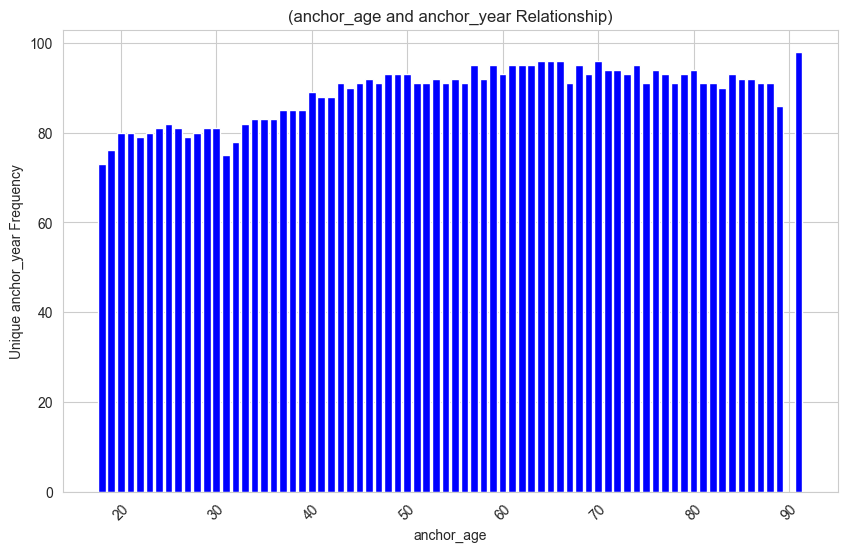

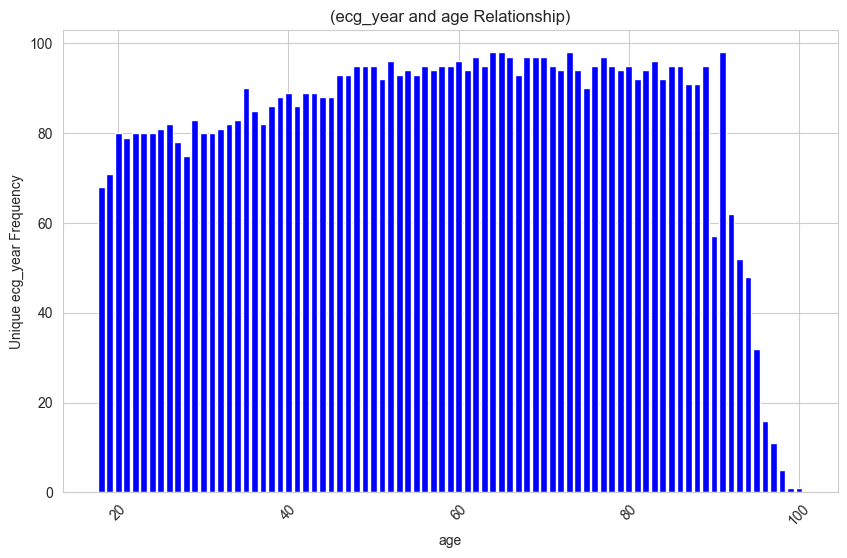

In [17]:
# ------------------- anchor_age/anchor_year ------------------------
# Raggruppa per anchor_age e conta i valori univoci di anchor_year correlato a ogni eta'
unique_age_year = patients_df.groupby('anchor_age')['anchor_year'].nunique().reset_index()
unique_age_year = unique_age_year.sort_values(by='anchor_age')  

def see_graphic(x, y, color, xlabel, ylabel, title):
    import matplotlib.pyplot as plt
    plt.figure(figsize=(10, 6))
    plt.bar(x, y, color=color)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(rotation=45)
    plt.show()

see_graphic(unique_age_year['anchor_age'], unique_age_year['anchor_year'], 'blue',
            "anchor_age", "Unique anchor_year Frequency", "(anchor_age and anchor_year Relationship)")

# ------------------- age/ecg_time ------------------------
# 'ecg_time' in datetime
patients_df['ecg_time'] = pd.to_datetime(patients_df['ecg_time'], errors='coerce')

# Estrazione dell'anno dall'ECG time
patients_df['ecg_year'] = patients_df['ecg_time'].dt.year
# Calcola il numero di età univoche per ogni anno ECG
unique_ecg_age = patients_df.groupby('age')['ecg_year'].nunique().reset_index()
unique_ecg_age = unique_ecg_age.sort_values(by='age')  

see_graphic(unique_ecg_age['age'], unique_ecg_age['ecg_year'], 'blue',
            "age", "Unique ecg_year Frequency", "(ecg_year and age Relationship)")



In [14]:
# Numero di date di nascita diverse associate ad ogni eta'
unique_age_year

,anchor_age,anchor_year
0,18.0,73
1,19.0,76
2,20.0,80
3,21.0,80
4,22.0,79
...,...,...
68,86.0,92
69,87.0,91
70,88.0,91
71,89.0,86


#####  **Osservazione:** 
#### troppo noise nelle colonne `anchor_year` e `ecg_time` , cancellare

---
### Distribuzione degli attributi numerici

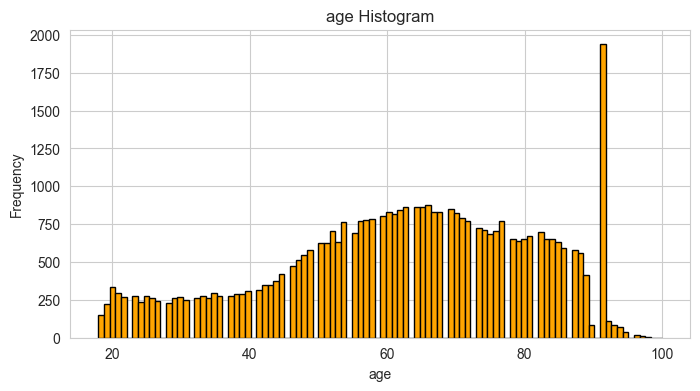

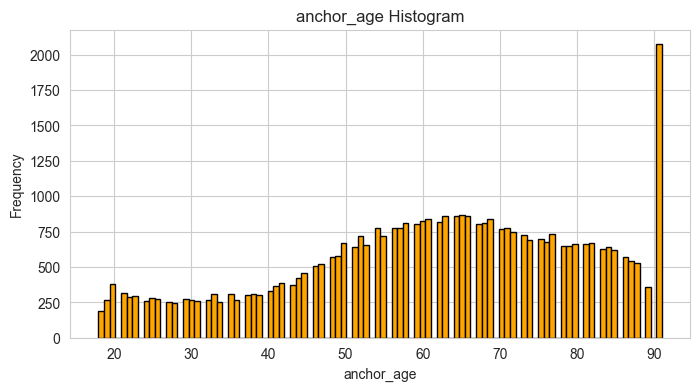

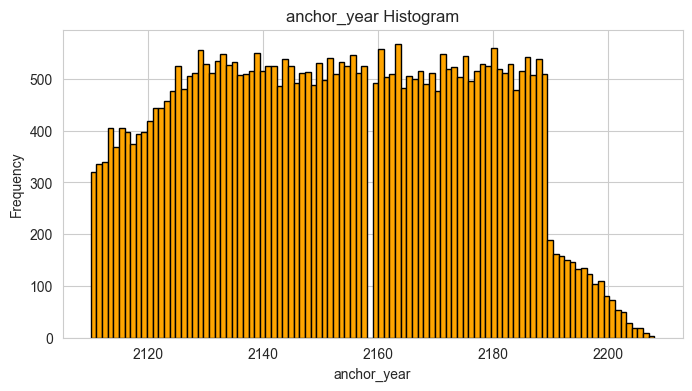

In [18]:
col = ['age', 'anchor_age', 'anchor_year']
for column in col:
    if pd.api.types.is_numeric_dtype(patients_df[column]):
        plt.figure(figsize=(8, 4))
        plt.hist(patients_df[column].dropna(), bins=100, edgecolor='black', color='orange')
        plt.title(f'{column} Histogram')
        plt.xlabel(column)
        plt.ylabel('Frequency')
        plt.show()

---
## Categorical data analysis

In [19]:
categorical_columns = ['diagnosis', 'gender']

In [33]:
patients_df['diagnosis'].nunique()

39628

In [20]:
# Cerca di dividere s in base alla posizione della seconda lettera maiuscola presente nella stringa. Se esistono esattamente due lettere maiuscole, la funzione restituisce la parte della stringa a partire dalla seconda lettera maiuscola (inclusa), eliminando eventuali spazi iniziali e finali. Altrimenti, restituisce la stringa originale senza modifiche.
def split_on_two_uppercase(s):
    uppercase_positions = [i for i, char in enumerate(s) if char.isupper()]
    if len(uppercase_positions) == 2:
        split_index = uppercase_positions[1]
        return s[split_index:].strip()
    else:
        return s

In [21]:
# upload file ICD-10
icd10_file_path = '../datasets/icd10cm-order-Jan-2021.txt'

# Estrai i codici e le descrizioni
icd10_data = []
with open(icd10_file_path, 'r') as file:
    for line in file:
        # Each line in the file: [index] [code] [0/1] [description] [redundant description]
        parts = line.strip().split(maxsplit=3)
        if len(parts) >= 4:
            code = parts[1]  
            description = parts[3] 
            descr_list = description.split("  ")
            # descr_list = re.split(r'(?<!^)(?=[A-Z])', description)
            if len(descr_list) == 1:
                descr_list = split_on_two_uppercase(descr_list[0])
                print(descr_list)
                description = descr_list
            else:
                description = descr_list[-1]
            icd10_data.append((code, description))
# Converti in DataFrame
icd10_df = pd.DataFrame(icd10_data, columns=['code', 'description'])
icd10_df


Acute gastrent d/t Norwalk agent and oth small round viruses Acute gastroenteropathy due to Norwalk agent and other small round viruses
Tuberculosis of intestines, peritoneum and mesenteric glands
Whooping cough due to Bordetella pertussis without pneumonia Whooping cough due to Bordetella pertussis without pneumonia
Whooping cough due to Bordetella parapertussis w/o pneumonia Whooping cough due to Bordetella parapertussis without pneumonia
Whooping cough due to other Bordetella species w/o pneumonia Whooping cough due to other Bordetella species without pneumonia
Gonocl infct of lower GU tract w periureth and acc glnd abcs Gonococcal infection of lower genitourinary tract with periurethral and accessory gland abscess
Other arthropod-borne viral fevers, not elsewhere classified
Exanthema subitum [sixth disease] due to human herpesvirus 6
Exanthema subitum [sixth disease] due to human herpesvirus 7
Chagas' disease with nervous system involvement, unspecified
Sequelae of other and unspec

,code,description
0,A00,Cholera
1,A000,"Cholera due to Vibrio cholerae 01, biovar cho..."
2,A001,"Cholera due to Vibrio cholerae 01, biovar eltor"
3,A009,"Cholera, unspecified"
4,A01,Typhoid and paratyphoid fevers
...,...,...
95353,Z9981,Dependence on supplemental oxygen
95354,Z9989,Dependence on other enabling machines and devices
95355,U07,Emergency use of U07
95356,U070,Vaping-related disorder


In [22]:
# Converte le stringhe in liste
patients_df['diagnosis'] = patients_df['diagnosis'].apply(eval)

In [7]:
patients_df['diagnosis']

0        [K7469, E871, R64, E875, I9581, J449, R188, V4...
1        [E7800, K219, Z87442, S72012A, I341, Z7901, Y9...
2        [R040, D696, I252, E785, I214, E780, I2510, Y9...
3        [I248, E785, Z794, Z8673, J449, E119, I129, N1...
4        [E871, R740, D649, E785, I10, K219, R197, E119...
                               ...                        
41410    [Z9049, F39, K219, F1021, R3911, K861, R52, R1...
41411                                         [R079, F419]
41412                                    [T7840XA, Y92099]
41413    [D649, D472, E440, D72819, Z6823, G959, J3801,...
41414    [H53469, R569, N390, E039, I619, I2510, R259, ...
Name: diagnosis, Length: 41415, dtype: object

In [23]:
# 1 diagnosis per riga
expanded_df = patients_df.explode('diagnosis')

In [6]:
expanded_df['diagnosis'].nunique()

9965

#### Controllo esistenza codici in diagnosis (**Pre-cleaning**)

In [24]:
# Filtra i codici non validi
invalid_codes = expanded_df.loc[~expanded_df['diagnosis'].isin(icd10_df['code']), 'diagnosis']

In [25]:
print("Codici non validi:", invalid_codes.unique())
print("Codici non validi NUM:", invalid_codes.nunique())
print("num cod non validi TOTALI", len(invalid_codes))


Codici non validi: ['T814XXA' 'S0210XA' 'T404X5A' 'T404X1A' 'T670XXA' 'S030XXA' 'T8351XA'
 'S0261XA' 'S023XXA' 'S028XXA' 'H4011X4' 'V4752XA' 'V4702XA' 'S0262XA'
 'S0265XA' 'T84042A' 'T84040A' 'H8149' 'T8359XA' 'T84041A' 'H4011X0'
 'I6020' 'Z2251' 'T8589XA' 'Z2252' 'T836XXA' 'I6021' 'T404X2A' 'M5107'
 'T84049A' 'V4762XA' 'I6022' 'S0267XA' 'S63144A' 'S060X4A' 'S0265XB'
 'T814XXD' 'S0263XA' 'S0264XA' 'H4011X2' 'S028XXB' 'T84043A' 'S023XXB'
 'T8586XA' 'T84048A']
Codici non validi NUM: 45
num cod non validi TOTALI 688


In [9]:
expanded_df

,study_id,subject_id,ecg_time,diagnosis,gender,age,anchor_year,anchor_age,dod,ts_ecg_path
0,40689238,10000032,2180-07-23 08:44:00,K7469,F,52.0,2180.0,52.0,2180-09-09,./time-series/10000032_40689238
0,40689238,10000032,2180-07-23 08:44:00,E871,F,52.0,2180.0,52.0,2180-09-09,./time-series/10000032_40689238
0,40689238,10000032,2180-07-23 08:44:00,R64,F,52.0,2180.0,52.0,2180-09-09,./time-series/10000032_40689238
0,40689238,10000032,2180-07-23 08:44:00,E875,F,52.0,2180.0,52.0,2180-09-09,./time-series/10000032_40689238
0,40689238,10000032,2180-07-23 08:44:00,I9581,F,52.0,2180.0,52.0,2180-09-09,./time-series/10000032_40689238
...,...,...,...,...,...,...,...,...,...,...
41414,41190887,19999987,2145-11-02 19:54:00,R259,F,57.0,2145.0,57.0,NaN,./time-series/19999987_41190887
41414,41190887,19999987,2145-11-02 19:54:00,G936,F,57.0,2145.0,57.0,NaN,./time-series/19999987_41190887
41414,41190887,19999987,2145-11-02 19:54:00,B961,F,57.0,2145.0,57.0,NaN,./time-series/19999987_41190887
41414,41190887,19999987,2145-11-02 19:54:00,N179,F,57.0,2145.0,57.0,NaN,./time-series/19999987_41190887


#### Diagnosi non classificate nel file testo 2021, ma considerati lo stesso per analisi a
#### macrogruppo delle categorie di diagnosi poiche cercando esistono ma la parte finale e' scritta
#### con un encode diverso (esempio con 'XA' finale).
#### Verranno salvati nel dataset ICD10 generale aggiornato con la descrizione della categoria di appartenenza

In [29]:
# Calcola la frequenza dei codici specifici di diagnosi
top_10_diagnosis = expanded_df['diagnosis'].value_counts().head(20)
print("Top 20 codici di diagnosi più frequenti:")
top_10_diagnosis

Top 20 codici di diagnosi più frequenti:


diagnosis
I10       17307
E785      12024
Z87891     7489
K219       6892
I2510      6255
F329       6042
E119       5422
N179       5402
I4891      4776
F419       4661
E039       4160
Z66        3471
D649       3440
Z7901      3336
N390       3310
R079       3023
I129       3017
F17200     2914
I509       2843
Z794       2836
Name: count, dtype: int64

In [27]:
# controllo
icd10_df[icd10_df['code'] == 'E875']

,code,description
4904,E875,Hyperkalemia


In [30]:
# estrapola descrizione per la top 20 dei codici piu frequenti
for num, code in enumerate(top_10_diagnosis.index):
    code_descr = icd10_df[icd10_df['code'] == code]
    print(f"top [{num+1}] | codice : [{code_descr['code'].iloc[0]}] | descrizione : [{code_descr['description'].iloc[0]}]")
    

top [1] | codice : [I10] | descrizione : [ Essential (primary) hypertension]
top [2] | codice : [E785] | descrizione : [Hyperlipidemia, unspecified]
top [3] | codice : [Z87891] | descrizione : [Personal history of nicotine dependence]
top [4] | codice : [K219] | descrizione : [ Gastro-esophageal reflux disease without esophagitis]
top [5] | codice : [I2510] | descrizione : [Atherosclerotic heart disease of native coronary artery without angina pectoris]
top [6] | codice : [F329] | descrizione : [ Major depressive disorder, single episode, unspecified]
top [7] | codice : [E119] | descrizione : [ Type 2 diabetes mellitus without complications]
top [8] | codice : [N179] | descrizione : [Acute kidney failure, unspecified]
top [9] | codice : [I4891] | descrizione : [Unspecified atrial fibrillation]
top [10] | codice : [F419] | descrizione : [Anxiety disorder, unspecified]
top [11] | codice : [E039] | descrizione : [Hypothyroidism, unspecified]
top [12] | codice : [Z66] | descrizione : [ Do 

### Distribuzione `diagnosis` per lettera alfabetica

In [32]:
expanded_df['alpha_diag_category'] = expanded_df['diagnosis'].str[0]
category_counts = expanded_df['alpha_diag_category'].value_counts()
print(category_counts)


alpha_diag_category
I    73846
Z    58630
E    56850
R    50371
F    31635
K    27724
N    20773
J    19667
D    18349
G    18297
M    16798
Y    12713
S    12313
C     7099
V     7054
T     6777
B     5971
H     4867
L     3804
A     3712
W     3639
Q     1079
X      699
O      557
P        4
Name: count, dtype: int64


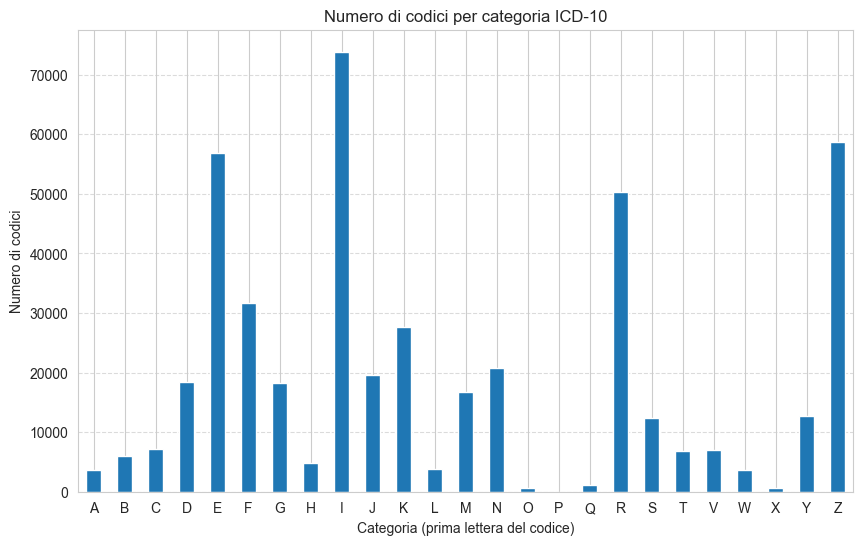

In [15]:
plt.figure(figsize=(10, 6))
category_counts.sort_index().plot(kind='bar')
plt.title('Numero di codici per categoria ICD-10')
plt.xlabel('Categoria (prima lettera del codice)')
plt.ylabel('Numero di codici')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


### Distribuzione per categoria di diagnosi

In [33]:
# Upload file with categorical range of icd10 code
icd10_category_df = pd.read_csv('../datasets/MAIN_IDC10_DISEASE_CHAPTERS.csv')

In [34]:
icd10_category_df = icd10_category_df.dropna()

In [18]:
type(icd10_category_df['Code_range'].iloc[0])

str

#### salvataggio, in `icd10_df`, dei codici non validi con descrizione delle categorie di appartenenza

In [35]:
# Estrapola la descrizione del gruppo categoriale corrispondente al singolo codice
def res_descriptio_category(code):
    for code_range in icd10_category_df['Code_range']:
        start, end = code_range.split('-')
        if start <= code <= end:
            return icd10_category_df[icd10_category_df['Code_range']==code_range]['Description'].iloc[0]

In [36]:
invalid_codes_list = list(set(invalid_codes))
new_rows = []

for code in invalid_codes_list:
    tmp_code = code[:3]
    description = res_descriptio_category(tmp_code)
    if not code in [new_rows_l['code'] for new_rows_l in new_rows]:
        new_rows.append({'code': code, 'description': description})

new_rows_df = pd.DataFrame(new_rows)
icd10_df = pd.concat([icd10_df, new_rows_df], ignore_index=True)
new_rows_df


,code,description
0,S028XXB,"Injury, poisoning and certain other consequenc..."
1,S0265XA,"Injury, poisoning and certain other consequenc..."
2,T84041A,"Injury, poisoning and certain other consequenc..."
3,S0263XA,"Injury, poisoning and certain other consequenc..."
4,T814XXA,"Injury, poisoning and certain other consequenc..."
5,T404X5A,"Injury, poisoning and certain other consequenc..."
6,S0261XA,"Injury, poisoning and certain other consequenc..."
7,S0267XA,"Injury, poisoning and certain other consequenc..."
8,V4752XA,External causes of morbidity
9,I6020,Diseases of the circulatory system


In [37]:
# Verificare se un codice appartiene a un range
def is_in_range(code, code_range):
    start, end = code_range.split('-')
    return start <= code <= end

In [38]:
# preparazione dizionario per contare la frequenza di codici non unici per ogni cotegoria presente fra i pazienti
range_counts = {row['Code_range']: 0 for _, row in icd10_category_df.iterrows()}
range_counts

{'A00-B99': 0,
 'C00-D49': 0,
 'D50-D89': 0,
 'E00-E89': 0,
 'F01-F99': 0,
 'G00-G99': 0,
 'H00-H59': 0,
 'H60-H95': 0,
 'I00-I99': 0,
 'J00-J99': 0,
 'K00-K95': 0,
 'L00-L99': 0,
 'M00-M99': 0,
 'N00-N99': 0,
 'O00-O9A': 0,
 'P00-P96': 0,
 'Q00-Q99': 0,
 'R00-R99': 0,
 'S00-T88': 0,
 'V00-Y99': 0,
 'Z00-Z99': 0}

In [39]:
# Conta le occorrenze dei codici per ogni range
for code in expanded_df['diagnosis']:
    for _, row in icd10_category_df.iterrows():
        if is_in_range(code, row['Code_range']):
            range_counts[row['Code_range']] += 1
            break  

In [24]:
range_counts

{'A00-B99': 9673,
 'C00-D49': 8601,
 'D50-D89': 16739,
 'E00-E89': 56594,
 'F01-F99': 31635,
 'G00-G99': 18242,
 'H00-H59': 3814,
 'H60-H95': 1052,
 'I00-I99': 73799,
 'J00-J99': 19667,
 'K00-K95': 27693,
 'L00-L99': 3804,
 'M00-M99': 16795,
 'N00-N99': 20450,
 'O00-O9A': 535,
 'P00-P96': 3,
 'Q00-Q99': 1071,
 'R00-R99': 50371,
 'S00-T88': 18978,
 'V00-Y99': 23925,
 'Z00-Z99': 57721}

In [40]:
results_categories_df = pd.DataFrame([
    {'code_range': code_range, 'count': count, 'description': icd10_category_df[icd10_category_df['Code_range'] == code_range]['Description'].values[0]}
    for code_range, count in range_counts.items()
])


In [88]:
# Salvataggio di icd10_df comprendente i codici non classificati in icd10_2021.txt + presenti in diagnosis di patients.csv
icd10_df.to_csv('../datasets/icd10_update_data.csv', index=False)

In [44]:
results_categories_df

,code_range,count,description
0,A00-B99,16178,Certain infectious and parasitic diseases
1,C00-D49,14320,Neoplasms
2,D50-D89,28065,Diseases of the blood and blood-forming organs...
3,E00-E89,94424,"Endocrine, nutritional and metabolic diseases"
4,F01-F99,53044,"Mental, Behavioral and Neurodevelopmental diso..."
5,G00-G99,30551,Diseases of the nervous system
6,H00-H59,6401,Diseases of the eye and adnexa
7,H60-H95,1816,Diseases of the ear and mastoid process
8,I00-I99,123322,Diseases of the circulatory system
9,J00-J99,32797,Diseases of the respiratory system


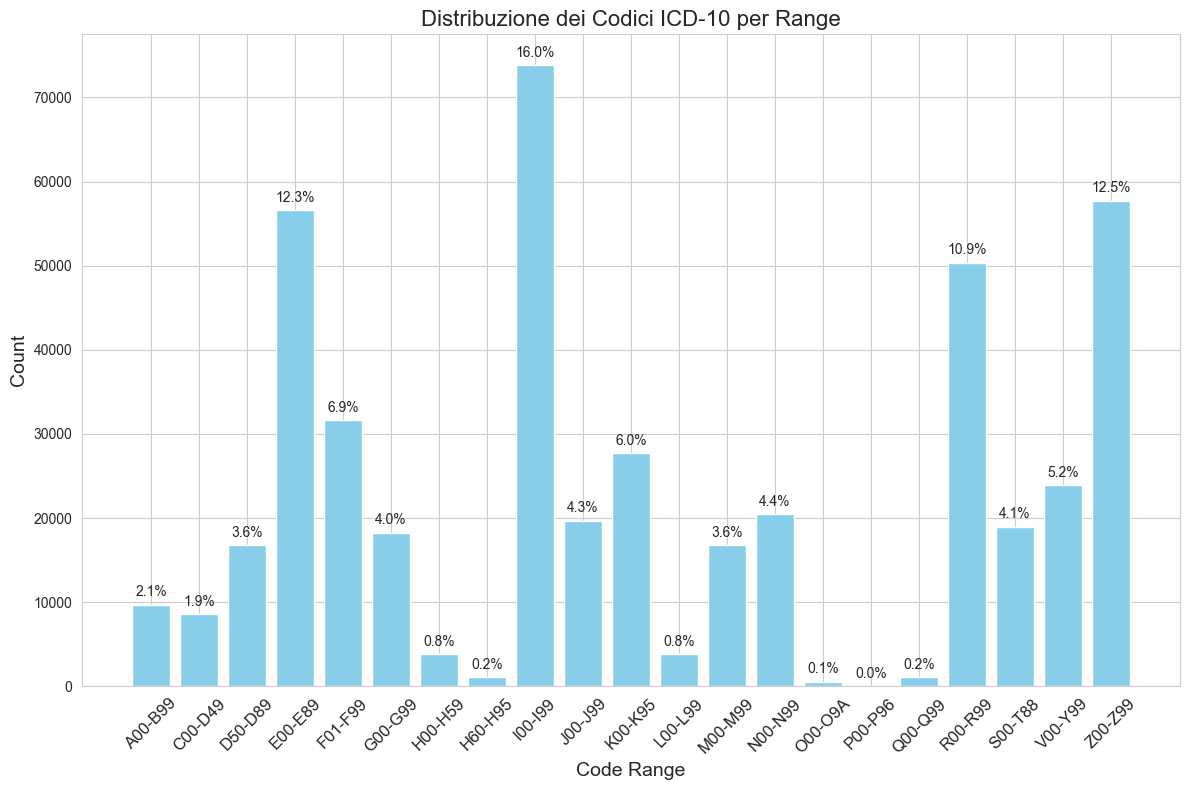

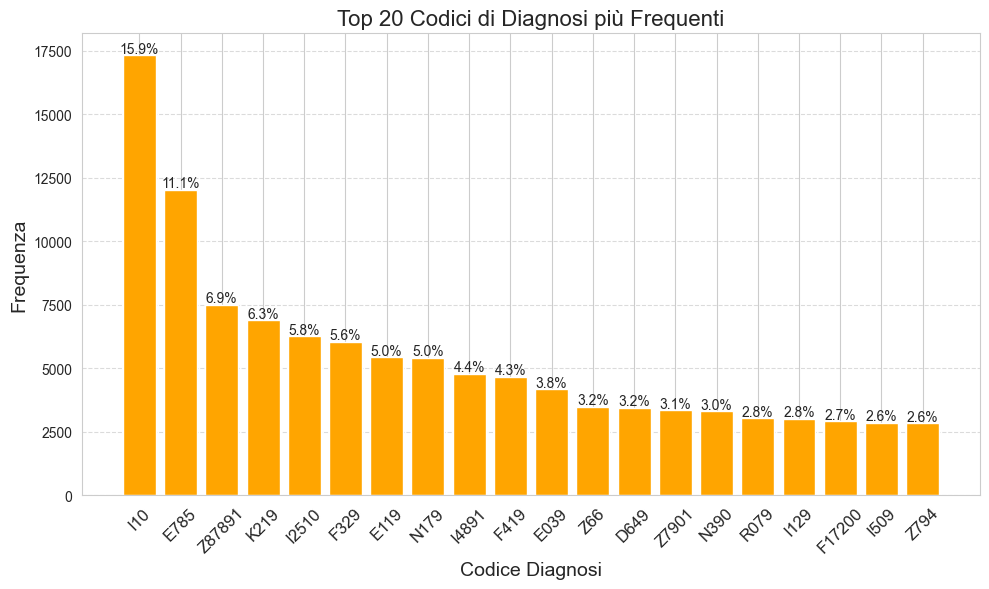

In [41]:
# --- Primo GRAFICO: Distribuzione dei Codici ICD-10 per Range ---
results_categories_df['percentage'] = (results_categories_df['count'] / results_categories_df['count'].sum()) * 100
plt.figure(figsize=(12, 8))
bars1 = plt.bar(results_categories_df['code_range'], results_categories_df['count'], color='skyblue')
# aggiunge percent alle barre
for bar, percent in zip(bars1, results_categories_df['percentage']):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 1000, f"{percent:.1f}%", ha='center', fontsize=10)
    
plt.title("Distribuzione dei Codici ICD-10 per Range", fontsize=16)
plt.xlabel("Code Range", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.tight_layout()
plt.show()

# --- Secondo GRAFICO: Top 10 Codici di Diagnosi più Frequenti ---
top_10_diagnosis_df = top_10_diagnosis.reset_index()
top_10_diagnosis_df.columns = ['diagnosis', 'count']

top_10_diagnosis_df['percentage'] = (top_10_diagnosis_df['count'] / top_10_diagnosis_df['count'].sum()) * 100
plt.figure(figsize=(10, 6))
bars2 = plt.bar(top_10_diagnosis_df['diagnosis'], top_10_diagnosis_df['count'], color='orange')
for bar, percent in zip(bars2, top_10_diagnosis_df['percentage']):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 100, f"{percent:.1f}%", ha='center', fontsize=10)
    
plt.title("Top 20 Codici di Diagnosi più Frequenti", fontsize=16)
plt.ylabel("Frequenza", fontsize=14)
plt.xlabel("Codice Diagnosi", fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [72]:
invalid_codes_list

['T670XXA',
 'T404X2A',
 'S63144A',
 'T814XXA',
 'S0267XA',
 'S060X4A',
 'T84042A',
 'T84048A',
 'H4011X0',
 'S023XXA',
 'T8351XA',
 'I6021',
 'I6020',
 'S030XXA',
 'Z2251',
 'T8589XA',
 'T84041A',
 'T814XXD',
 'S0263XA',
 'S023XXB',
 'T836XXA',
 'S0265XB',
 'T84040A',
 'I6022',
 'M5107',
 'V4702XA',
 'H4011X4',
 'S028XXB',
 'S0262XA',
 'V4752XA',
 'H8149',
 'S0261XA',
 'T8586XA',
 'T404X5A',
 'T404X1A',
 'T84043A',
 'S0210XA',
 'S028XXA',
 'T8359XA',
 'T84049A',
 'Z2252',
 'H4011X2',
 'V4762XA',
 'S0265XA',
 'S0264XA']

In [78]:
icd10_df

,code,description
0,A00,Cholera
1,A000,"Vibrio cholerae 01, biovar cholerae"
2,A001,"Vibrio cholerae 01, biovar eltor"
3,A009,"Cholera, unspecified"
4,A01,Typhoid and paratyphoid fevers
...,...,...
95398,Z2252,Factors influencing health status and contact ...
95399,H4011X2,Diseases of the eye and adnexa
95400,V4762XA,External causes of morbidity
95401,S0265XA,"Injury, poisoning and certain other consequenc..."


In [77]:
icd10_df[icd10_df['code']=='S023XXA']

,code,description
95367,S023XXA,"Injury, poisoning and certain other consequenc..."


#### **Distribuzione diagnosi per genere**

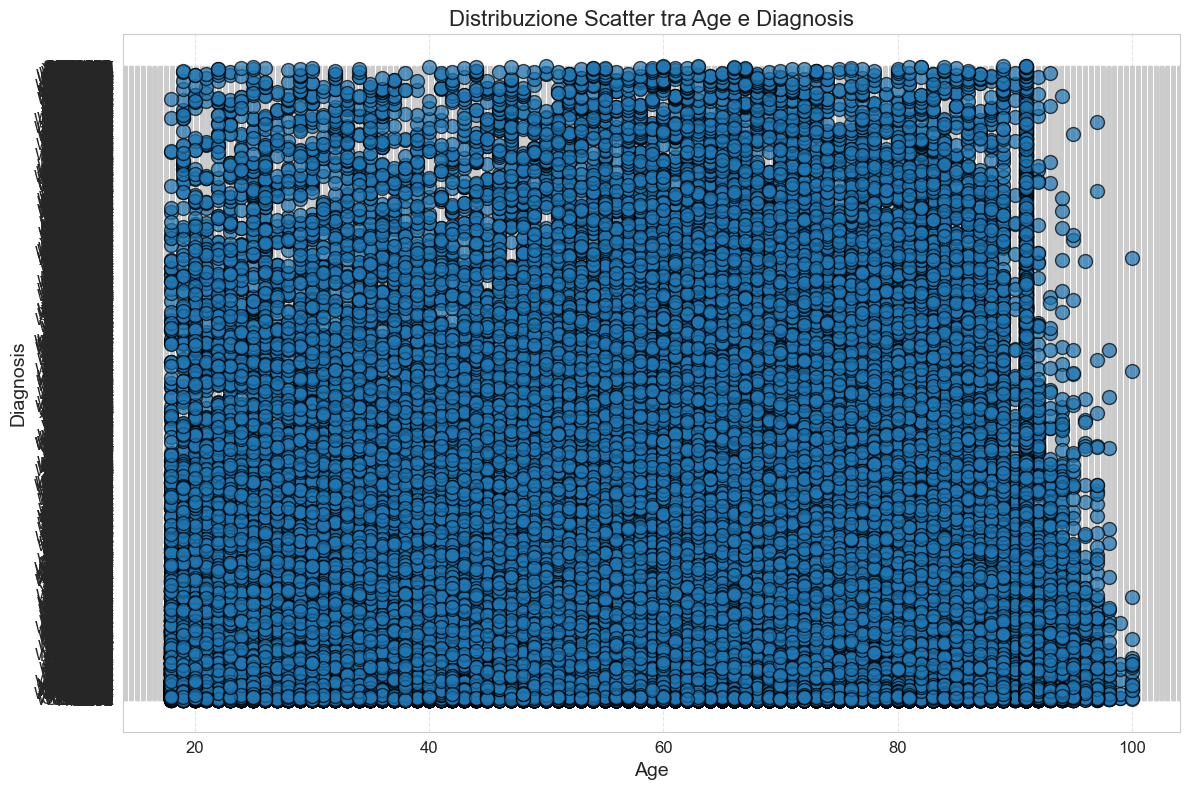

In [29]:
plt.figure(figsize=(12, 8))
plt.scatter(
    expanded_df['age'],
    expanded_df['diagnosis'],
    alpha=0.7,
    edgecolors='k',
    s=100
)

plt.title("Distribuzione Scatter tra Age e Diagnosis", fontsize=16)
plt.xlabel("Age", fontsize=14)
plt.ylabel("Diagnosis", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(alpha=0.5, linestyle='--')
plt.tight_layout()
plt.show()


Nessuna osservazione

In [48]:
top_10_diagnosis_df = top_10_diagnosis.reset_index()

In [84]:
# Filtra i pazienti con età > 50
age_filtered_df = expanded_df[expanded_df['age'] < 40]


In [90]:
age_filtered_df

,study_id,subject_id,ecg_time,diagnosis,gender,age,anchor_year,anchor_age,dod,ts_ecg_path,alpha_diag_category
9,47678751,10002528,2168-12-11 00:30:00,R29818,F,26.0,2168.0,26.0,NaN,./time-series/10002528_47678751,R
9,47678751,10002528,2168-12-11 00:30:00,F329,F,26.0,2168.0,26.0,NaN,./time-series/10002528_47678751,F
9,47678751,10002528,2168-12-11 00:30:00,D509,F,26.0,2168.0,26.0,NaN,./time-series/10002528_47678751,D
9,47678751,10002528,2168-12-11 00:30:00,K219,F,26.0,2168.0,26.0,NaN,./time-series/10002528_47678751,K
9,47678751,10002528,2168-12-11 00:30:00,D519,F,26.0,2168.0,26.0,NaN,./time-series/10002528_47678751,D
...,...,...,...,...,...,...,...,...,...,...,...
41410,43267699,19998444,2155-06-03 22:42:00,Z9889,M,38.0,2155.0,38.0,NaN,./time-series/19998444_43267699,Z
41410,43267699,19998444,2155-06-03 22:42:00,K5900,M,38.0,2155.0,38.0,NaN,./time-series/19998444_43267699,K
41410,43267699,19998444,2155-06-03 22:42:00,G8929,M,38.0,2155.0,38.0,NaN,./time-series/19998444_43267699,G
41412,42489677,19999733,2152-07-08 21:38:00,T7840XA,F,19.0,2152.0,19.0,NaN,./time-series/19999733_42489677,T


In [75]:
filtered_codes = age_filtered_df['diagnosis'].unique()

In [93]:
icd10_category_df

,"Chapter,",Code_range,Description
0,1.0,A00-B99,Certain infectious and parasitic diseases
1,2.0,C00-D49,Neoplasms
2,3.0,D50-D89,Diseases of the blood and blood-forming organs...
3,4.0,E00-E89,"Endocrine, nutritional and metabolic diseases"
4,5.0,F01-F99,"Mental, Behavioral and Neurodevelopmental diso..."
5,6.0,G00-G99,Diseases of the nervous system
6,7.0,H00-H59,Diseases of the eye and adnexa
7,8.0,H60-H95,Diseases of the ear and mastoid process
8,9.0,I00-I99,Diseases of the circulatory system
9,10.0,J00-J99,Diseases of the respiratory system


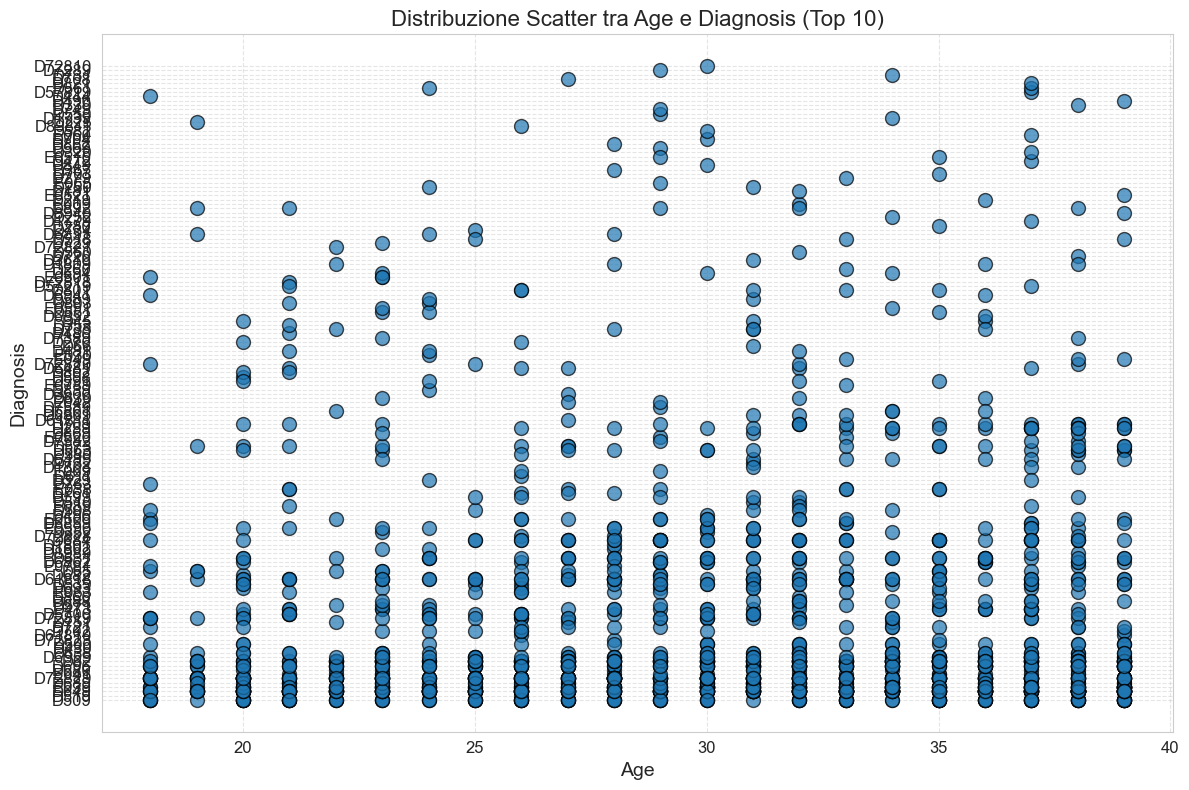

In [89]:
# Filtrare expanded_df
filtered_df = age_filtered_df[age_filtered_df['diagnosis'].isin(icd10_df['code'][3000:4000])]

plt.figure(figsize=(12, 8))
plt.scatter(
    filtered_df['age'],
    filtered_df['diagnosis'], 
    alpha=0.7,
    edgecolors='k',
    s=100
)

plt.title("Distribuzione Scatter tra Age e Diagnosis (Top 10)", fontsize=16)
plt.xlabel("Age", fontsize=14)
plt.ylabel("Diagnosis", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(alpha=0.5, linestyle='--')
plt.tight_layout()
plt.show()


Nessuna osservazione

In [95]:
columns_to_save = ['Code_range', 'Description']
icd10_category_df_selected = icd10_category_df[columns_to_save]

icd10_category_df_selected.to_csv("../datasets/icd10_category.csv", index=False)


In [89]:
top_10_diagnosis_df

,diagnosis,count,percentage
0,I10,17307,15.933530
1,E785,12024,11.069785
2,Z87891,7489,6.894679
3,K219,6892,6.345056
4,I2510,6255,5.758608
5,F329,6042,5.562512
6,E119,5422,4.991714
7,N179,5402,4.973301
8,I4891,4776,4.396980
9,F419,4661,4.291107


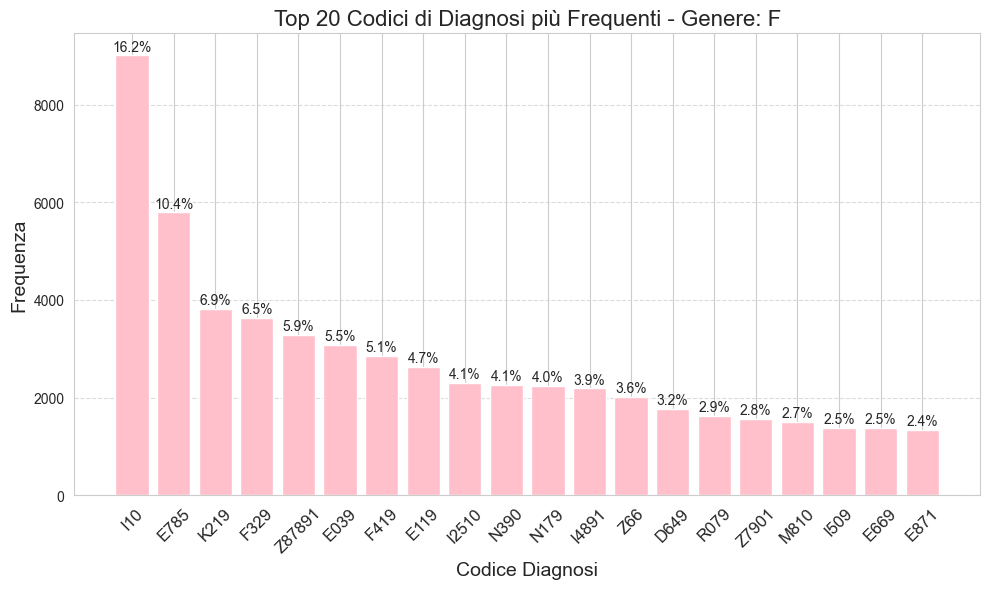

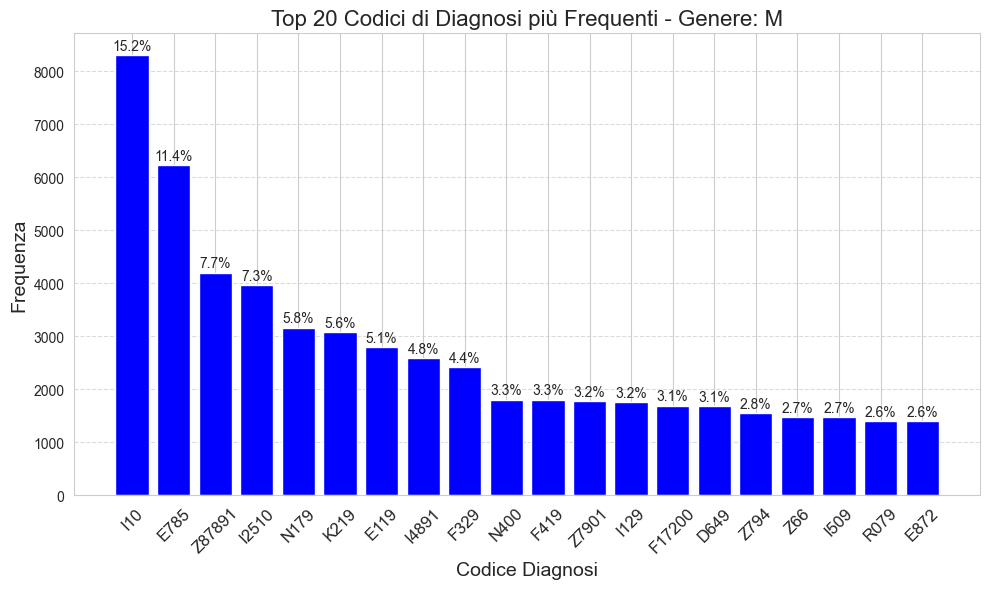

In [43]:
gender_groups = patients_df.groupby('gender')
for gender, group in gender_groups:
    diagnosis_counts = group['diagnosis'].explode().value_counts()
    top_10_diagnosis = diagnosis_counts.head(20)
    top_10_diagnosis_df = top_10_diagnosis.reset_index()
    top_10_diagnosis_df.columns = ['diagnosis', 'count']
    top_10_diagnosis_df['percentage'] = (top_10_diagnosis_df['count'] / top_10_diagnosis_df['count'].sum()) * 100
    plt.figure(figsize=(10, 6))
    bars = plt.bar(top_10_diagnosis_df['diagnosis'], top_10_diagnosis_df['count'], color='blue' if gender == 'M' else 'pink')
    for bar, percent in zip(bars, top_10_diagnosis_df['percentage']):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, height + 100, f"{percent:.1f}%", ha='center', fontsize=10)

    plt.title(f"Top 20 Codici di Diagnosi più Frequenti - Genere: {gender}", fontsize=16)
    plt.ylabel("Frequenza", fontsize=14)
    plt.xlabel("Codice Diagnosi", fontsize=14)
    plt.xticks(rotation=45, fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


---
#### `dod`
#### Semplificazione date di morti coi vivi con true e false binario per istogramma

In [11]:
patients_df_cp = patients_df.copy()

In [12]:
patients_df['dod'].unique()

array(['2180-09-09', nan, '2193-08-26', ..., '2118-07-29', '2188-05-21',
       '2178-12-08'], dtype=object)

In [13]:
# Sostituzione dei NaN in 'dod' con '0000-00-00'
patients_df_cp['dod'] = patients_df_cp['dod'].fillna('0000-00-00')
print(patients_df_cp['dod'].unique())


['2180-09-09' '0000-00-00' '2193-08-26' ... '2118-07-29' '2188-05-21'
 '2178-12-08']


In [14]:
patients_df_cp['dod'] = np.where(patients_df_cp['dod'] == '0000-00-00', 0, 1)

In [19]:
# Numero di morti e vivi
category_counts = patients_df_cp['dod'].value_counts()
print("vivo: 0 | morto: 1\n", category_counts)


vivo: 0 | morto: 1
 dod
0    33405
1     8010
Name: count, dtype: int64


#### `gender`

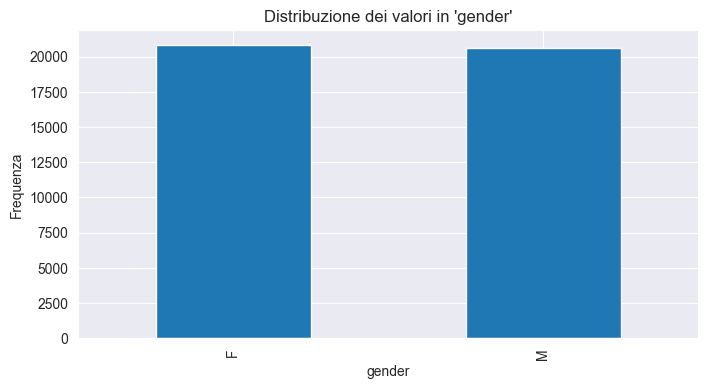

In [17]:
for col in ['gender']:
    plt.figure(figsize=(8, 4))
    patients_df[col].value_counts().plot(kind='bar')
    plt.title(f"Distribuzione dei valori in '{col}'")
    plt.xlabel(col)
    plt.ylabel("Frequenza")
    plt.show()


In [23]:
patients_df.columns

Index(['study_id', 'subject_id', 'ecg_time', 'diagnosis', 'gender', 'age',
       'anchor_year', 'anchor_age', 'dod', 'ts_ecg_path', 'ecg_year'],
      dtype='object')

---
### Analisi matrix correlation

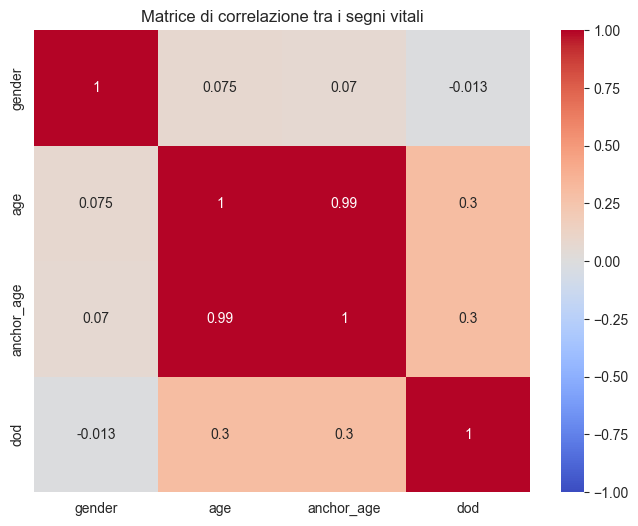

In [20]:
patients_df_cp['gender'] = patients_df_cp['gender'].map({'M': 0, 'F': 1})

correlation_matrix = patients_df_cp[['gender', 'age', 'anchor_age', 'dod']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matrice di correlazione tra i segni vitali")
plt.show()


#### alta correlazione age e anchor_age. butto via anchor_age